# Active Learning Results Analysis

This notebook loads experiment results and produces:
1. **Main plot**: Accuracy vs. number of labeled images (BALD vs Random) with +/-1 std bands
2. **Class balance plot**: How BALD vs Random differ in class composition over rounds
3. **Secondary plots**: Precision, Recall, F1 curves
4. **Training loss plot**: Loss per round for the appendix
5. **Paired t-test table**: Statistical significance results

Run `python experiments/run_comparison.py` first to generate the results.

In [11]:
import json
import os
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure plots
sns.set_theme(style='whitegrid', context='paper', font_scale=1.3)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.bbox'] = 'tight'

RESULTS_DIR = '../experiments/results'

# Auto-detect seeds from available result files
active_files = glob.glob(os.path.join(RESULTS_DIR, 'active_bald_seed_*.json'))
SEEDS = sorted([int(re.search(r'seed_(\d+)', f).group(1)) for f in active_files])

print(f'Results directory: {os.path.abspath(RESULTS_DIR)}')
print(f'Auto-detected seeds: {SEEDS}')

Results directory: C:\Users\hp\.gemini\antigravity-ide\scratch\active-learning-xray\experiments\results
Auto-detected seeds: [42, 123, 456]


## 1. Load Results

In [12]:
def load_histories(results_dir, strategy_prefix, seeds):
    """Load result histories for a strategy across all seeds."""
    all_histories = {}
    for seed in seeds:
        filename = f'{strategy_prefix}_seed_{seed}.json'
        filepath = os.path.join(results_dir, filename)
        if os.path.exists(filepath):
            with open(filepath) as f:
                data = json.load(f)
            all_histories[seed] = data['history']
            print(f'  Loaded {filename}: {len(data["history"])} rounds')
        else:
            print(f'  WARNING: {filename} not found')
    return all_histories

print('Loading BALD active learning results:')
active_histories = load_histories(RESULTS_DIR, 'active_bald', SEEDS)

print('\nLoading random baseline results:')
random_histories = load_histories(RESULTS_DIR, 'random', SEEDS)

print(f'\nLoaded {len(active_histories)} active + {len(random_histories)} random runs')

Loading BALD active learning results:
  Loaded active_bald_seed_42.json: 8 rounds
  Loaded active_bald_seed_123.json: 8 rounds
  Loaded active_bald_seed_456.json: 8 rounds

Loading random baseline results:
  Loaded random_seed_42.json: 8 rounds
  Loaded random_seed_123.json: 8 rounds
  Loaded random_seed_456.json: 8 rounds

Loaded 3 active + 3 random runs


In [13]:
def histories_to_df(histories, strategy_name):
    """Convert histories dict to a flat DataFrame."""
    rows = []
    for seed, history in histories.items():
        for entry in history:
            row = {
                'seed': seed,
                'strategy': strategy_name,
                'n_labeled': entry['n_labeled'],
                'accuracy': entry['accuracy'],
                'precision': entry['precision'],
                'recall': entry['recall'],
                'f1': entry['f1'],
                'round': entry['round'],
            }
            # Add class balance stats if available
            if 'pool_stats' in entry:
                ps = entry['pool_stats']
                row['labeled_normal'] = ps.get('labeled_normal', 0)
                row['labeled_pneumonia'] = ps.get('labeled_pneumonia', 0)
                total = row['labeled_normal'] + row['labeled_pneumonia']
                row['normal_ratio'] = row['labeled_normal'] / total if total > 0 else 0
            rows.append(row)
    return pd.DataFrame(rows)

df_active = histories_to_df(active_histories, 'BALD (Active)')
df_random = histories_to_df(random_histories, 'Random')
df_all = pd.concat([df_active, df_random], ignore_index=True)

print(f'Total data points: {len(df_all)}')
df_all.head()

Total data points: 48


,seed,strategy,n_labeled,accuracy,precision,recall,f1,round,labeled_normal,labeled_pneumonia,normal_ratio
0,42,BALD (Active),100,0.629808,0.628019,1.000000,0.771513,1,50,50,0.500000
1,42,BALD (Active),125,0.750000,0.722433,0.974359,0.829694,2,62,63,0.496000
2,42,BALD (Active),150,0.775641,0.745098,0.974359,0.844444,3,74,76,0.493333
3,42,BALD (Active),175,0.770833,0.740741,0.974359,0.841639,4,86,89,0.491429
4,42,BALD (Active),200,0.705128,0.683274,0.984615,0.806723,5,98,102,0.490000


## 2. Main Plot: Accuracy vs. Labels Used

This is the primary VIVA visual -- shows BALD consistently achieving higher accuracy with fewer labels.

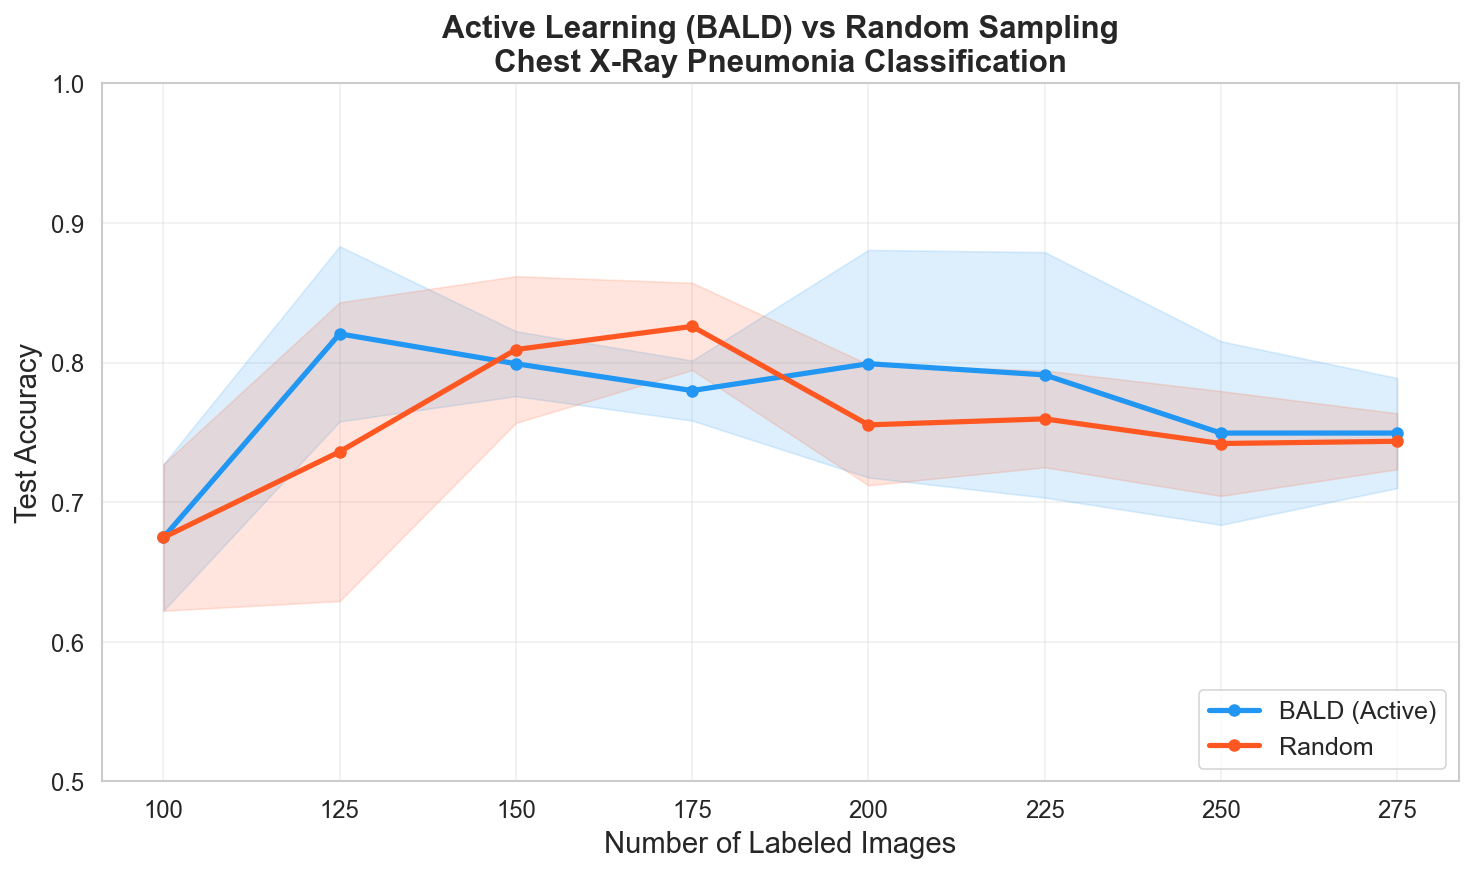

Saved: accuracy_vs_labels.png


In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'BALD (Active)': '#2196F3', 'Random': '#FF5722'}

for strategy, color in colors.items():
    df_s = df_all[df_all['strategy'] == strategy]
    
    # Group by n_labeled and compute mean/std across seeds
    grouped = df_s.groupby('n_labeled')['accuracy'].agg(['mean', 'std']).reset_index()
    
    ax.plot(grouped['n_labeled'], grouped['mean'], 
            color=color, linewidth=2.5, label=strategy, marker='o', markersize=5)
    ax.fill_between(grouped['n_labeled'], 
                    grouped['mean'] - grouped['std'],
                    grouped['mean'] + grouped['std'],
                    color=color, alpha=0.15)

ax.set_xlabel('Number of Labeled Images', fontsize=14)
ax.set_ylabel('Test Accuracy', fontsize=14)
ax.set_title('Active Learning (BALD) vs Random Sampling\nChest X-Ray Pneumonia Classification', 
             fontsize=15, fontweight='bold')
ax.legend(fontsize=12, loc='lower right')
ax.set_ylim(0.5, 1.0)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'accuracy_vs_labels.png'))
plt.show()
print('Saved: accuracy_vs_labels.png')

## 3. Class Balance Plot

Shows how BALD vs Random differ in the class composition of their labeled sets over rounds.
A key insight: if BALD over-selects one class, the model can become biased.

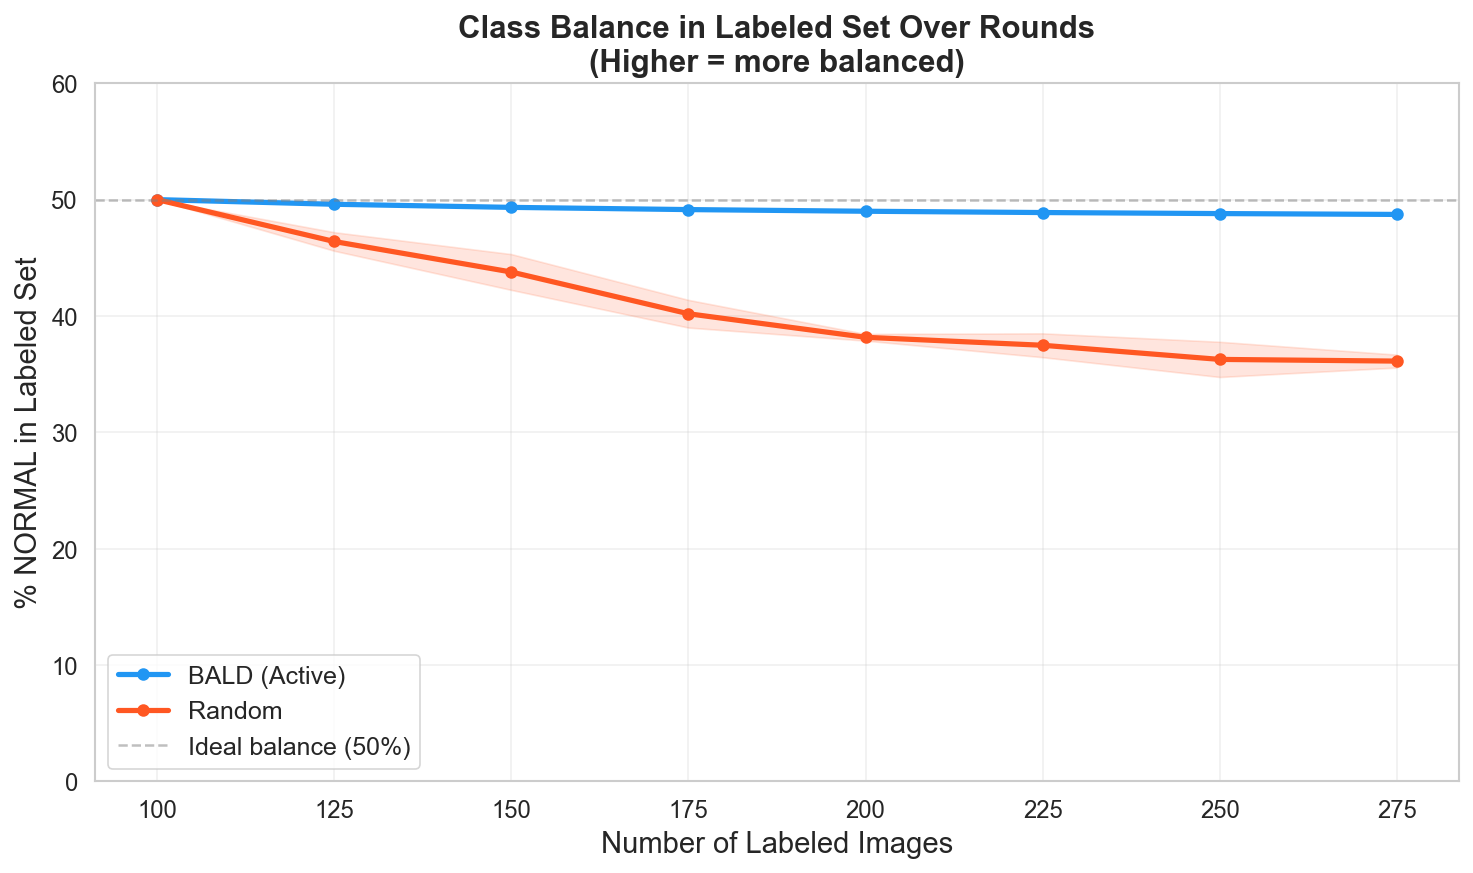

Saved: class_balance.png


In [15]:
if 'normal_ratio' in df_all.columns:
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for strategy, color in colors.items():
        df_s = df_all[df_all['strategy'] == strategy]
        grouped = df_s.groupby('n_labeled')['normal_ratio'].agg(['mean', 'std']).reset_index()
        
        ax.plot(grouped['n_labeled'], grouped['mean'] * 100, 
                color=color, linewidth=2.5, label=strategy, marker='o', markersize=5)
        ax.fill_between(grouped['n_labeled'], 
                        (grouped['mean'] - grouped['std']) * 100,
                        (grouped['mean'] + grouped['std']) * 100,
                        color=color, alpha=0.15)
    
    ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='Ideal balance (50%)')
    ax.set_xlabel('Number of Labeled Images', fontsize=14)
    ax.set_ylabel('% NORMAL in Labeled Set', fontsize=14)
    ax.set_title('Class Balance in Labeled Set Over Rounds\n(Higher = more balanced)', 
                 fontsize=15, fontweight='bold')
    ax.legend(fontsize=12)
    ax.set_ylim(0, 60)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'class_balance.png'))
    plt.show()
    print('Saved: class_balance.png')
else:
    print('No pool_stats data available for class balance plot')

## 4. Secondary Plots: Precision, Recall, F1

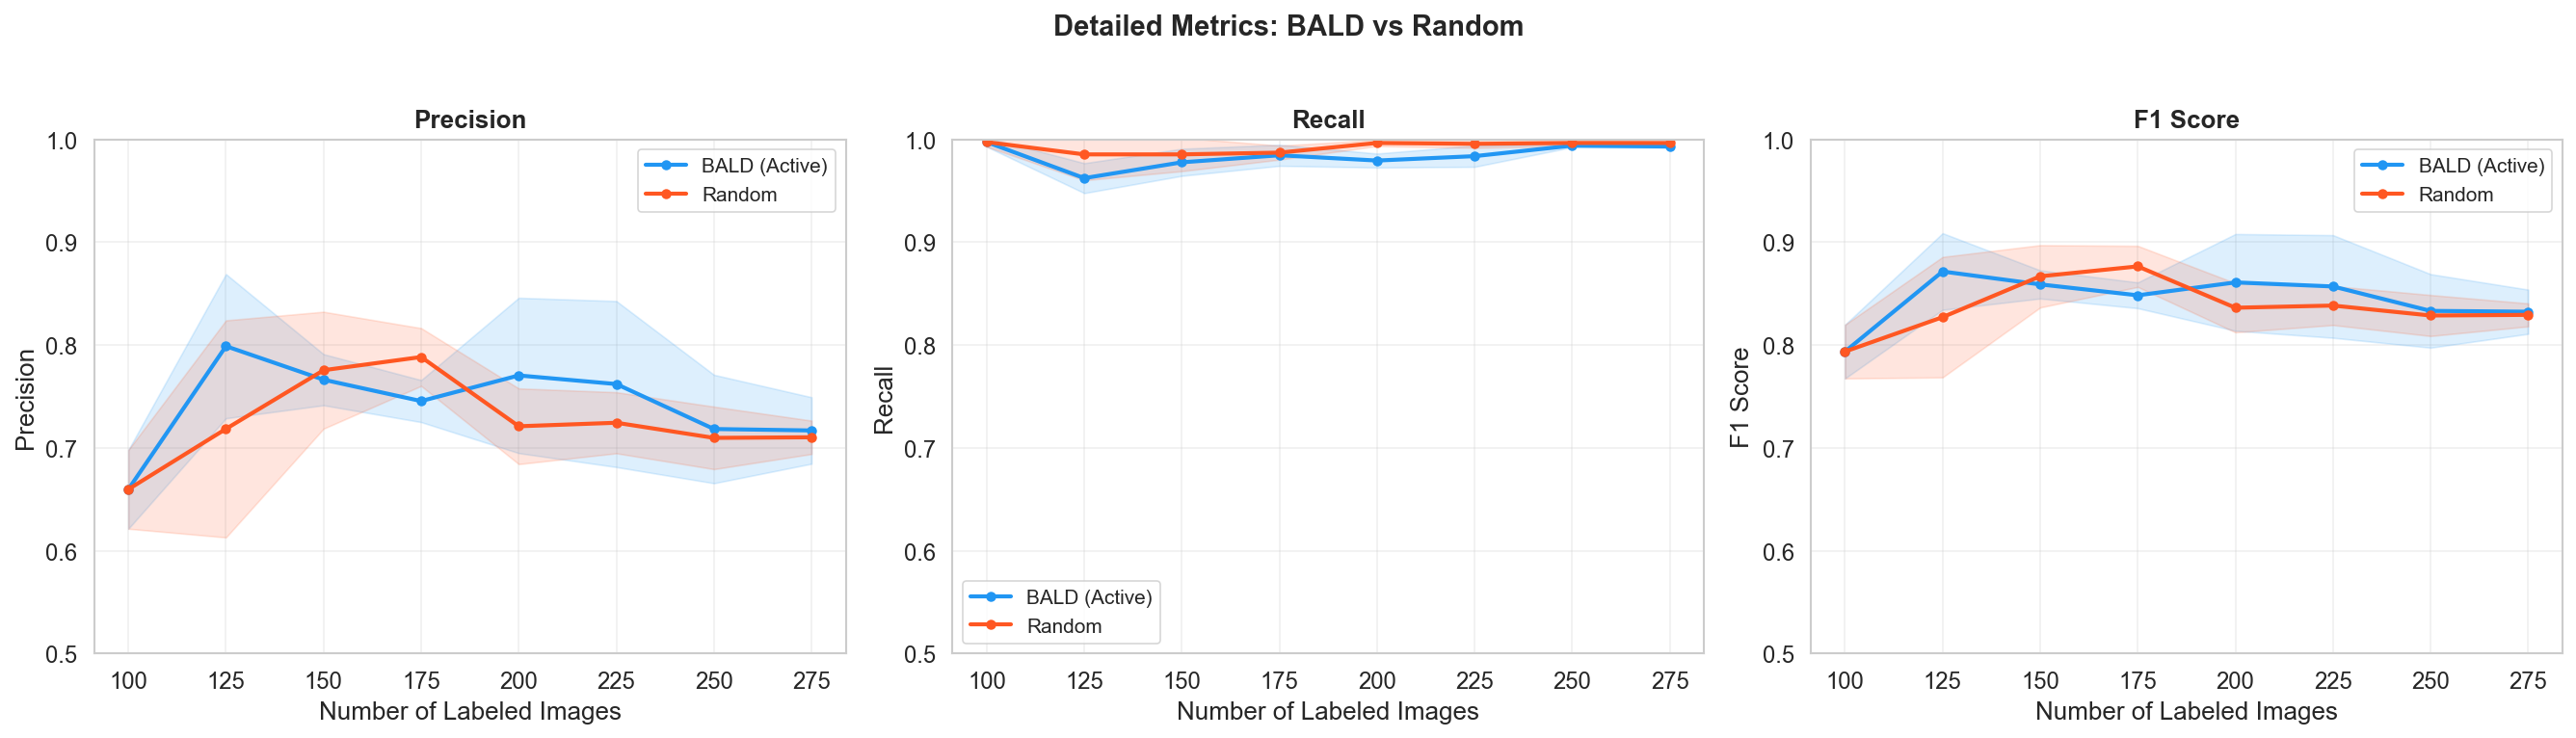

Saved: detailed_metrics.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ['precision', 'recall', 'f1']
titles = ['Precision', 'Recall', 'F1 Score']

for ax, metric, title in zip(axes, metrics, titles):
    for strategy, color in colors.items():
        df_s = df_all[df_all['strategy'] == strategy]
        grouped = df_s.groupby('n_labeled')[metric].agg(['mean', 'std']).reset_index()
        
        ax.plot(grouped['n_labeled'], grouped['mean'],
                color=color, linewidth=2, label=strategy, marker='o', markersize=4)
        ax.fill_between(grouped['n_labeled'],
                        grouped['mean'] - grouped['std'],
                        grouped['mean'] + grouped['std'],
                        color=color, alpha=0.15)
    
    ax.set_xlabel('Number of Labeled Images')
    ax.set_ylabel(title)
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=10)
    ax.set_ylim(0.5, 1.0)
    ax.grid(True, alpha=0.3)

plt.suptitle('Detailed Metrics: BALD vs Random', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'detailed_metrics.png'))
plt.show()
print('Saved: detailed_metrics.png')

## 5. Training Loss per Round (Appendix)

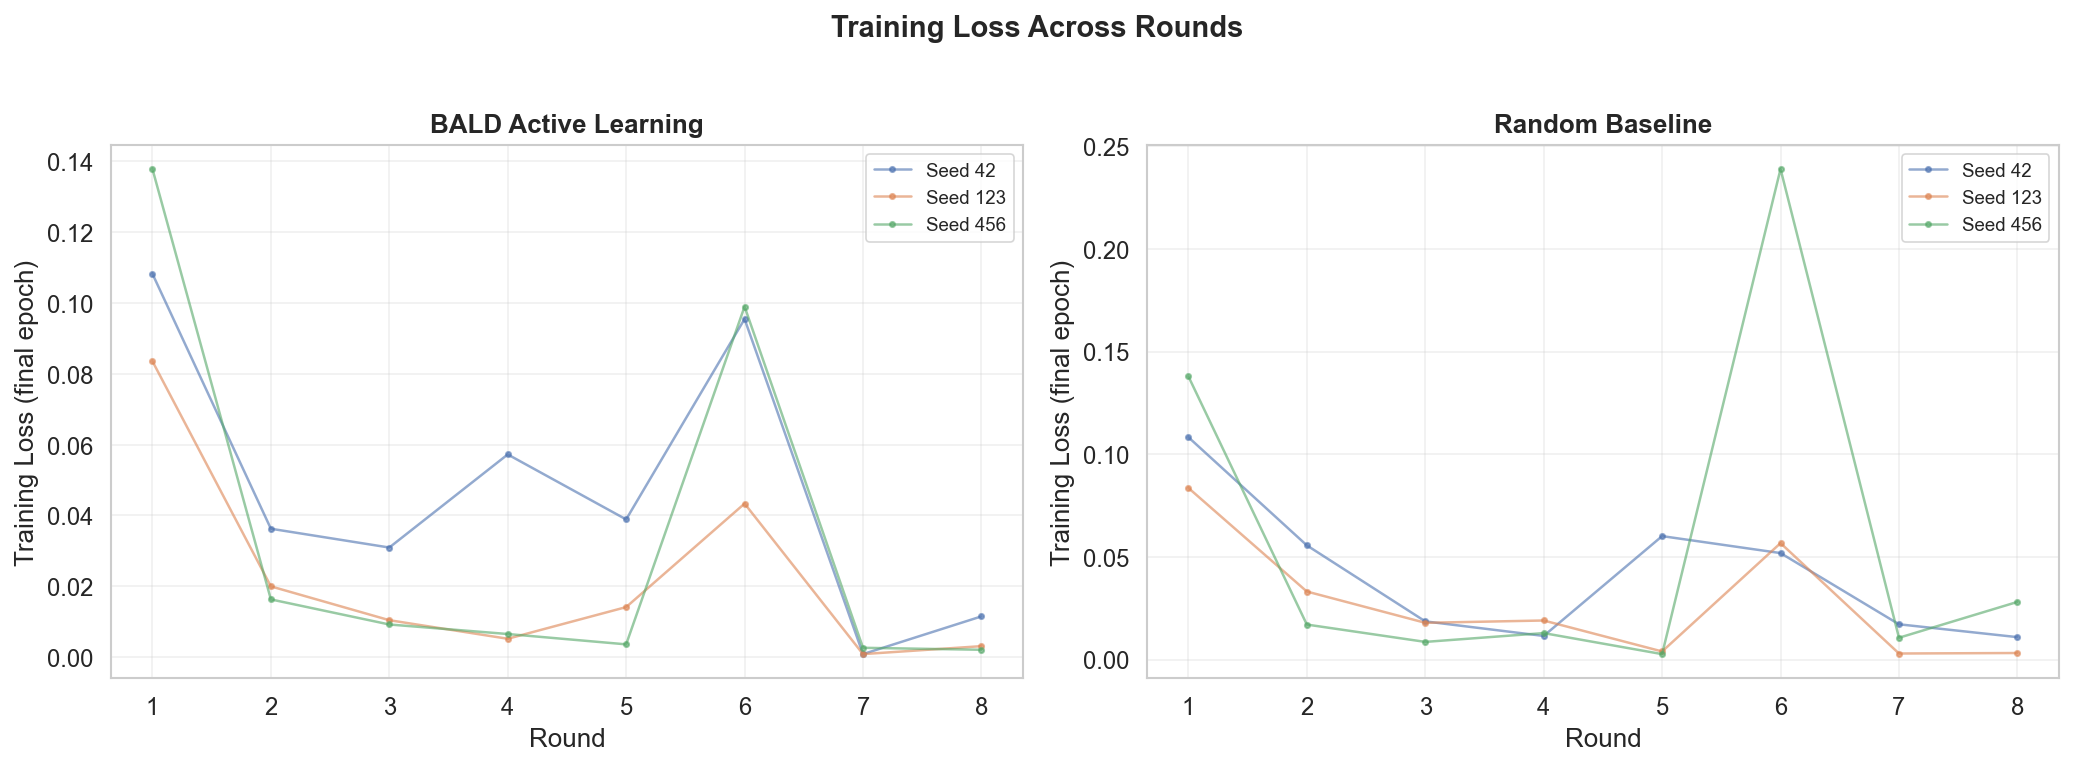

Saved: training_loss.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (histories, title) in zip(axes, 
    [(active_histories, 'BALD Active Learning'), (random_histories, 'Random Baseline')]):
    
    for seed, history in histories.items():
        # Get the final epoch loss for each round
        round_nums = [e['round'] for e in history]
        final_losses = [e['epoch_losses'][-1] for e in history if e['epoch_losses']]
        rounds_with_loss = [e['round'] for e in history if e['epoch_losses']]
        
        ax.plot(rounds_with_loss, final_losses, marker='.', alpha=0.6, label=f'Seed {seed}')
    
    ax.set_xlabel('Round')
    ax.set_ylabel('Training Loss (final epoch)')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Training Loss Across Rounds', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'training_loss.png'))
plt.show()
print('Saved: training_loss.png')

## 6. Paired t-test Results

At matched label-budget checkpoints, compare accuracy between BALD and random across seeds using a paired t-test.

In [8]:
# Load or compute t-test results
ttest_csv = os.path.join(RESULTS_DIR, 'ttest_results.csv')

if os.path.exists(ttest_csv):
    df_ttest = pd.read_csv(ttest_csv)
    print('Loaded existing t-test results:')
else:
    # Recompute
    import sys
    sys.path.insert(0, '..')
    from src.stats_test import run_paired_ttest
    # Auto-compute checkpoints
    all_n_labeled = sorted(df_all['n_labeled'].unique())
    checkpoints = all_n_labeled[1::2]  # every other checkpoint
    df_ttest = run_paired_ttest(RESULTS_DIR, SEEDS, checkpoints=list(checkpoints))
    print('Computed t-test results:')

# Display as a nicely formatted table
display_df = df_ttest.copy()
display_df['active'] = display_df.apply(
    lambda r: f"{r['active_mean']:.4f} +/- {r['active_std']:.4f}" 
    if pd.notna(r['active_mean']) else 'N/A', axis=1)
display_df['random'] = display_df.apply(
    lambda r: f"{r['random_mean']:.4f} +/- {r['random_std']:.4f}" 
    if pd.notna(r['random_mean']) else 'N/A', axis=1)
display_df['p_value_fmt'] = display_df['p_value'].apply(
    lambda p: f'{p:.4f}' if pd.notna(p) else 'N/A')

result_table = display_df[['checkpoint', 'active', 'random', 'p_value_fmt', 'significant']]
result_table.columns = ['# Labels', 'BALD (mean +/- std)', 'Random (mean +/- std)', 'p-value', 'Significant?']
display(result_table)

Loaded existing t-test results:


,# Labels,BALD (mean +/- std),Random (mean +/- std),p-value,Significant?
0,150,0.7991 +/- 0.0232,0.8093 +/- 0.0525,0.6124,No
1,200,0.7991 +/- 0.0815,0.7553 +/- 0.0433,0.5065,No
2,250,0.7495 +/- 0.0657,0.7420 +/- 0.0375,0.9046,No
3,300,0.7495 +/- 0.0394,0.7436 +/- 0.0200,0.7956,No


## 7. Summary Statistics

In [9]:
print('=== EXPERIMENT SUMMARY ===')
print(f'Seeds used: {SEEDS}')
print(f'Number of BALD runs: {len(active_histories)}')
print(f'Number of Random runs: {len(random_histories)}')

if active_histories and random_histories:
    # Final accuracies
    active_final = [h[-1]['accuracy'] for h in active_histories.values()]
    random_final = [h[-1]['accuracy'] for h in random_histories.values()]
    
    print(f'\nFinal Accuracy (at max labels):')
    print(f'  BALD:   {np.mean(active_final):.4f} +/- {np.std(active_final, ddof=1):.4f}')
    print(f'  Random: {np.mean(random_final):.4f} +/- {np.std(random_final, ddof=1):.4f}')
    
    # Best accuracy at any checkpoint
    active_best = df_active.groupby('seed')['accuracy'].max()
    random_best = df_random.groupby('seed')['accuracy'].max()
    
    print(f'\nBest Accuracy (peak across all rounds):')
    print(f'  BALD:   {active_best.mean():.4f} +/- {active_best.std(ddof=1):.4f}')
    print(f'  Random: {random_best.mean():.4f} +/- {random_best.std(ddof=1):.4f}')
    
    # Time stats
    active_times = [sum(e['round_time_sec'] for e in h) for h in active_histories.values()]
    random_times = [sum(e['round_time_sec'] for e in h) for h in random_histories.values()]
    
    print(f'\nTotal Time per Run:')
    print(f'  BALD:   {np.mean(active_times)/60:.1f} +/- {np.std(active_times, ddof=1)/60:.1f} min')
    print(f'  Random: {np.mean(random_times)/60:.1f} +/- {np.std(random_times, ddof=1)/60:.1f} min')

=== EXPERIMENT SUMMARY ===
Seeds used: [42, 123, 456]
Number of BALD runs: 3
Number of Random runs: 3

Final Accuracy (at max labels):
  BALD:   0.7495 +/- 0.0394
  Random: 0.7436 +/- 0.0200

Best Accuracy (peak across all rounds):
  BALD:   0.8333 +/- 0.0506
  Random: 0.8323 +/- 0.0370

Total Time per Run:
  BALD:   281.8 +/- 20.3 min
  Random: 20.5 +/- 0.1 min
